In [1]:
import json
import os

import h5py
import numpy
from matplotlib import pyplot
from scipy.ndimage import gaussian_filter

from helper.scattering import scattering_curve_gpu

def load_inputs(result_dir, syn_dir, h5_path):
    """Everything the comparison needs, in one dictionary."""
    summary = json.load(open(os.path.join(result_dir, "summary.json")))
    truth_cfg = json.load(open(os.path.join(syn_dir, "truth.json")))
    with h5py.File(h5_path, "r") as f:
        dark = f["rho"][truth_cfg["dark_index"]].astype(numpy.float32)
        dv = float(f["dv"][()])
    q_data, dI_data = numpy.loadtxt(os.path.join(syn_dir, "deltaI.csv"), delimiter=",", unpack=True)
    return {
        "summary": summary,
        "truth_cfg": truth_cfg,
        "best": numpy.load(os.path.join(result_dir, "rank0_density.npy")),
        "truth": numpy.load(os.path.join(syn_dir, "truth_light.npy")),
        "dark": dark,
        "dv": dv,
        "q_data": q_data,
        "dI_data": dI_data,
    }


def lowpass(density, qmax, dv):
    """Gaussian filter keeping structure up to about qmax (sigma = 1/qmax Å)."""
    return gaussian_filter(density, 1.0 / (qmax * dv))


def density_metrics(rec, truth, dark):
    """r_diff: correlation of the changes; rel_err: 0 perfect, 1 = no better than the dark state."""
    d_rec, d_true = (rec - dark).ravel(), (truth - dark).ravel()
    r_diff = numpy.corrcoef(d_rec, d_true)[0, 1]
    rel_err = numpy.linalg.norm(rec - truth) / numpy.linalg.norm(truth - dark)
    return r_diff, rel_err


def print_metrics(best, truth, dark, qmax, dv):
    """Metrics at full resolution and at the data's resolution."""
    for label, f in [("full resolution", lambda d: d), ("data resolution", lambda d: lowpass(d, qmax, dv))]:
        r_diff, rel_err = density_metrics(f(best), f(truth), f(dark))
        print(f"{label:16s}  r_diff {r_diff:.3f}  rel_err {rel_err:.3f}")


def plot_projections(images, titles, kws, suptitle=None, axis=2):
    """One row of projections (summed along `axis`), each with a colorbar below."""
    fig, ax = pyplot.subplots(1, len(images), figsize=(4 * len(images), 4.5), layout="constrained")
    if suptitle:
        fig.suptitle(suptitle)
    for a, img, title, kw in zip(ax, images, titles, kws):
        im = a.imshow(img.sum(axis=axis), **kw)
        a.set_title(title)
        a.axis("off")
        fig.colorbar(im, ax=a, orientation="horizontal", location="bottom", shrink=0.8, label=r"e/Å$^2$")
    pyplot.show()


def plot_densities(truth, best, yld, suptitle=None):
    """Truth and best on the same scale, and their difference."""
    vmax = max(truth.sum(axis=0).max(), best.sum(axis=0).max())
    dmax = numpy.abs((best - truth).sum(axis=0)).max()
    plot_projections(
        [truth, best, best - truth],
        ["truth", f"best (rank 0, yield {yld:.2f})", "difference (best - truth)"],
        [dict(vmin=0, vmax=vmax), dict(vmin=0, vmax=vmax), dict(cmap="RdBu_r", vmin=-dmax, vmax=dmax)],
        suptitle,
    )


def plot_changes(truth, best, dark):
    """True change, found change and remaining error, all relative to the dark state."""
    panels = [truth - dark, best - dark, best - truth]
    vmax = max(numpy.abs(p.sum(axis=0)).max() for p in panels)
    kw = dict(cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    plot_projections(panels, ["true change (truth - dark)", "found change (best - dark)", "error (best - truth)"],
                     [kw, kw, kw])



def scattering(density, dv, rho_bulk, dark_fit, padding):
    """I(q) of one density with the dark state's solvent parameters (NumPy)."""
    q, I = scattering_curve_gpu(density, dv, rho_bulk, dark_fit["drho"], dark_fit["shell"], padding, qmax=None)
    return q.get(), I.get()


def delta_I(I_light, I_dark, q, q_data, yld, scale):
    """ΔI on the data's q-values, for a given yield and absolute scale."""
    return numpy.interp(q_data, q, yld * scale * (I_light - I_dark))


def plot_scattering(q, I_truth, I_best, qmax, q_data, dI_data, dI_truth, dI_best, yld_truth, yld_best):
    fig, ax = pyplot.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    ax[0].plot(q, I_truth, label="truth")
    ax[0].plot(q, I_best, label="best (rank 0)")
    ax[0].axvline(qmax, color="grey", ls=":", label="fitted q-range")
    ax[0].set(yscale="log", xlabel="q (1/Å)", ylabel="I(q)", xlim=(0, 2 * qmax), title="scattering")
    ax[0].legend()

    ax[1].plot(q_data, dI_data, "k.", label="data")
    ax[1].plot(q_data, dI_truth, label=f"truth (yield {yld_truth:.2f})")
    ax[1].plot(q_data, dI_best, label=f"best (yield {yld_best:.2f})")
    ax[1].axhline(0, color="k", lw=0.5)
    ax[1].set(xlabel="q (1/Å)", ylabel="ΔI", title="difference scattering")
    ax[1].legend()
    pyplot.show()


full resolution   r_diff 0.917  rel_err 0.456
data resolution   r_diff 0.856  rel_err 0.618


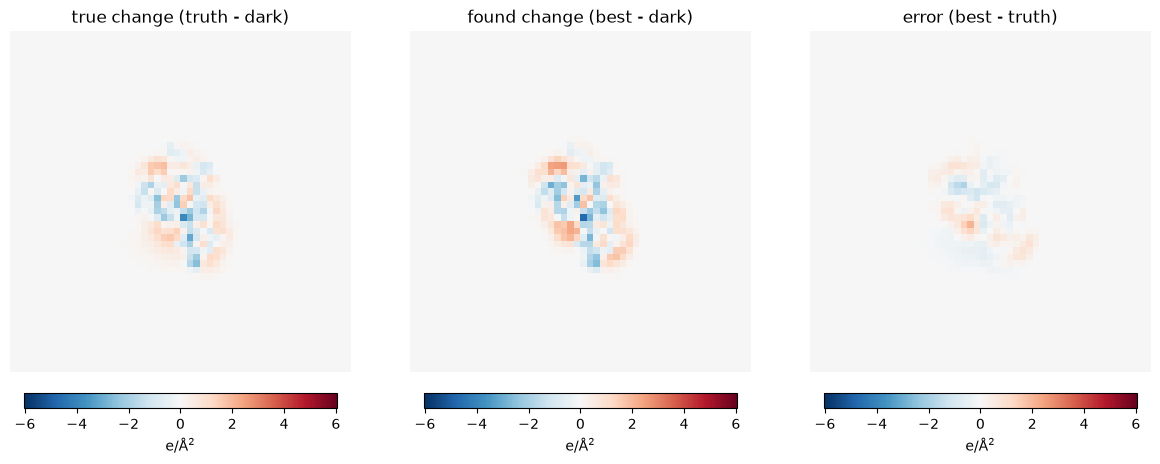

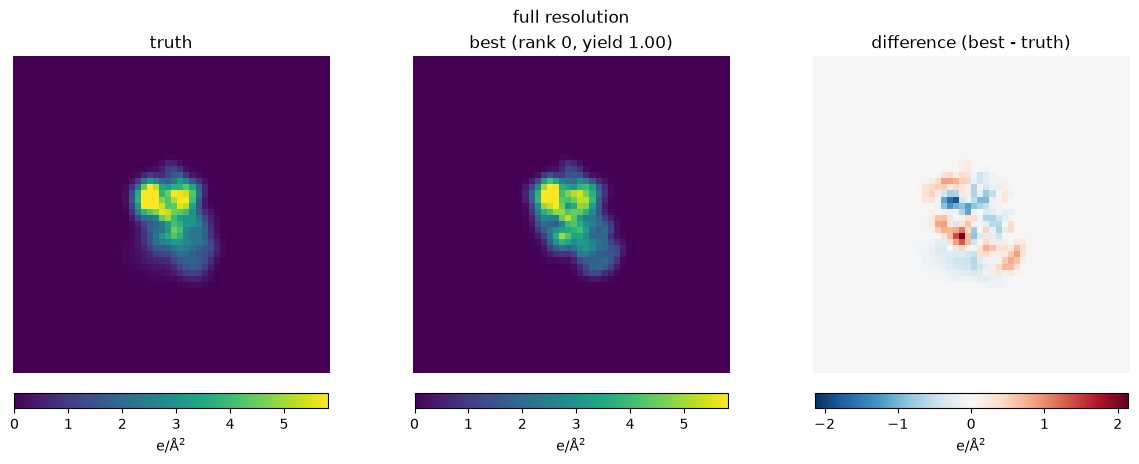

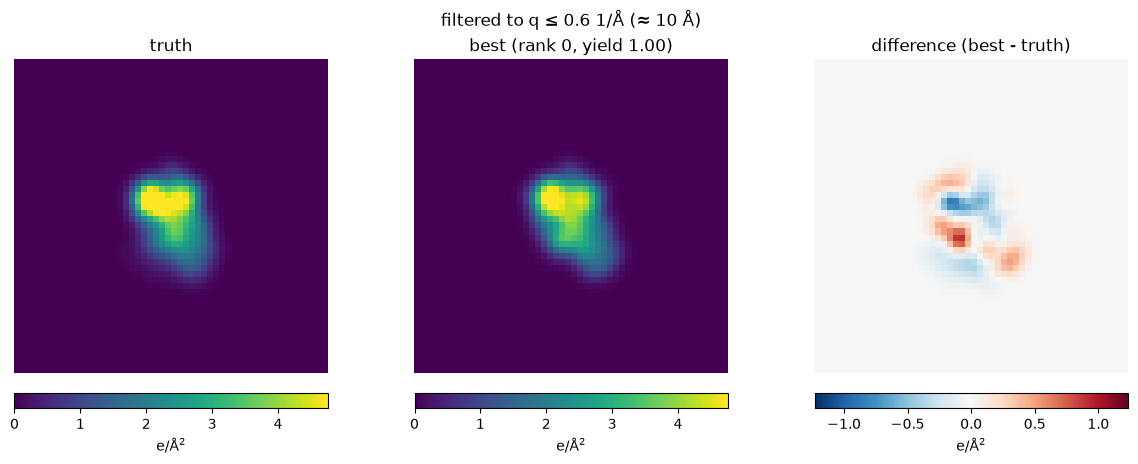

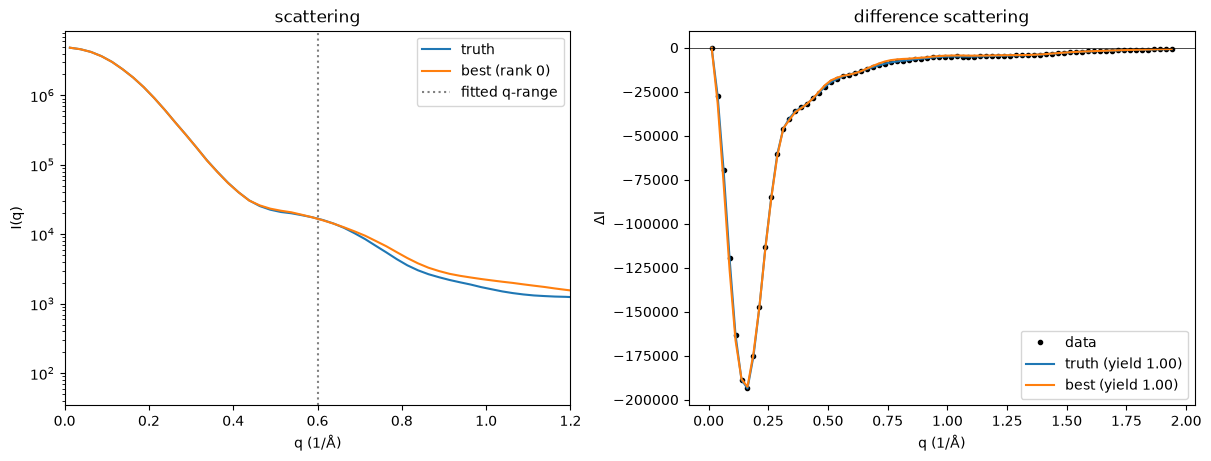

In [2]:
result_dir = "results/synthetic_class1_vacuum"
syn_dir = "data/synthetic_class1_vacuum"
h5_path = "data/1crn_41bb_1d61dv_5co.h5"

d = load_inputs(result_dir, syn_dir, h5_path)
settings, dark_fit = d["summary"]["settings"], d["summary"]["dark_fit"]
yld_best, yld_truth = d["summary"]["candidates"][0]["yield"], d["truth_cfg"]["pa_yield"]
qmax, dv = settings["qmax"], d["dv"]

# Densities
print_metrics(d["best"], d["truth"], d["dark"], qmax, dv)
plot_changes(d["truth"], d["best"], d["dark"])
plot_densities(d["truth"], d["best"], yld_best, "full resolution")
plot_densities(lowpass(d["truth"], qmax, dv), lowpass(d["best"], qmax, dv), yld_best,
               f"filtered to q ≤ {qmax} 1/Å (≈ {2 * numpy.pi / qmax:.0f} Å)")

# Scattering
q, I_dark = scattering(d["dark"], dv, settings["rho_bulk"], dark_fit, settings["padding"])
_, I_truth = scattering(d["truth"], dv, settings["rho_bulk"], dark_fit, settings["padding"])
_, I_best = scattering(d["best"], dv, settings["rho_bulk"], dark_fit, settings["padding"])
dI_truth = delta_I(I_truth, I_dark, q, d["q_data"], yld_truth, dark_fit["scale"])
dI_best = delta_I(I_best, I_dark, q, d["q_data"], yld_best, dark_fit["scale"])
plot_scattering(q, I_truth, I_best, qmax, d["q_data"], d["dI_data"], dI_truth, dI_best, yld_truth, yld_best)

full resolution   r_diff 0.910  rel_err 0.441
data resolution   r_diff 0.870  rel_err 0.543


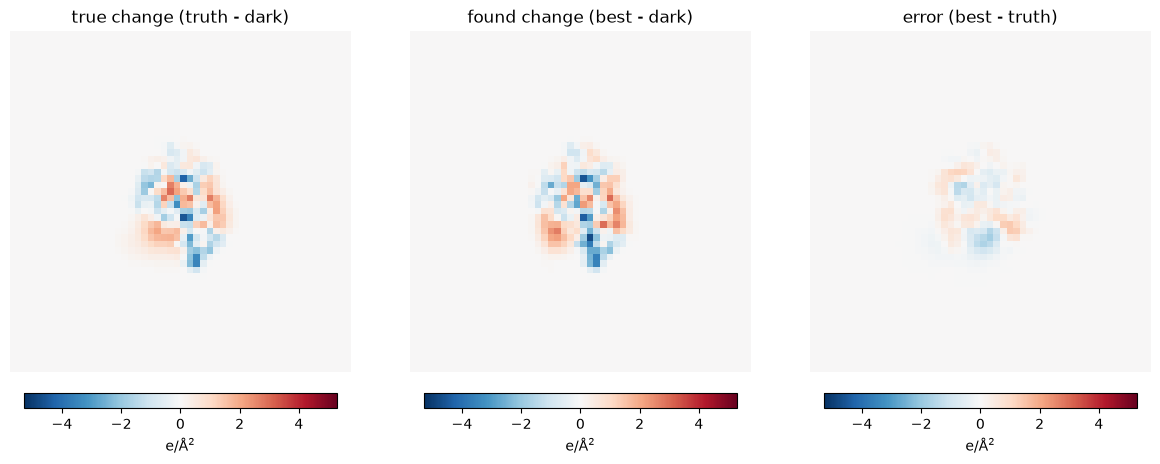

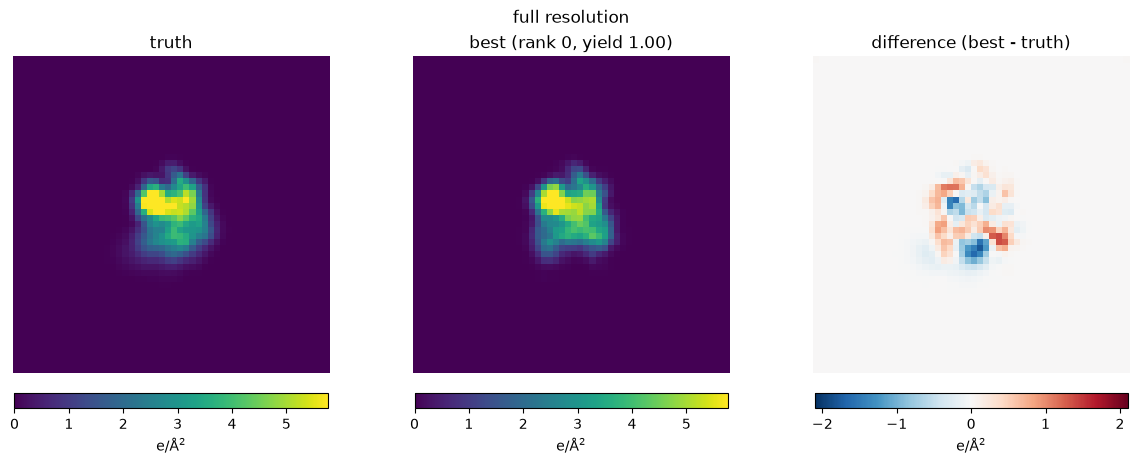

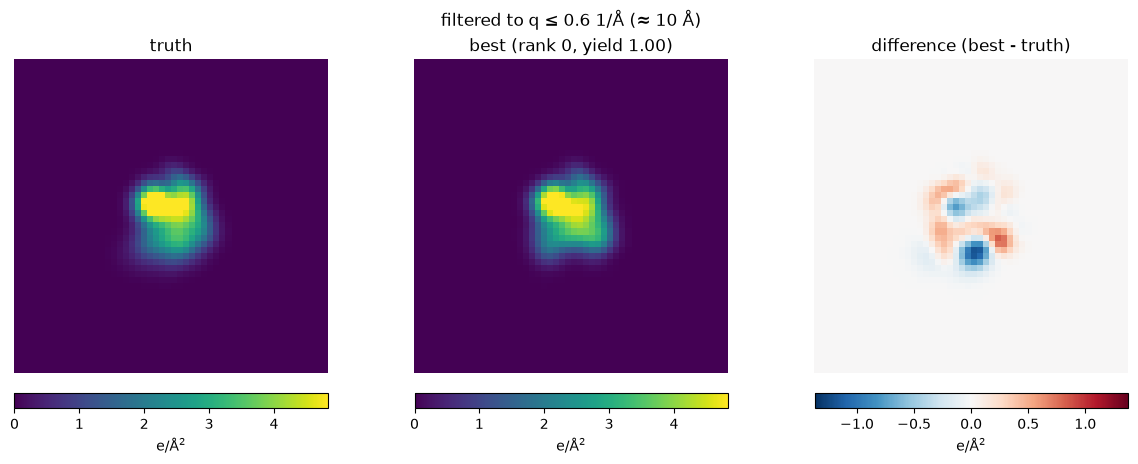

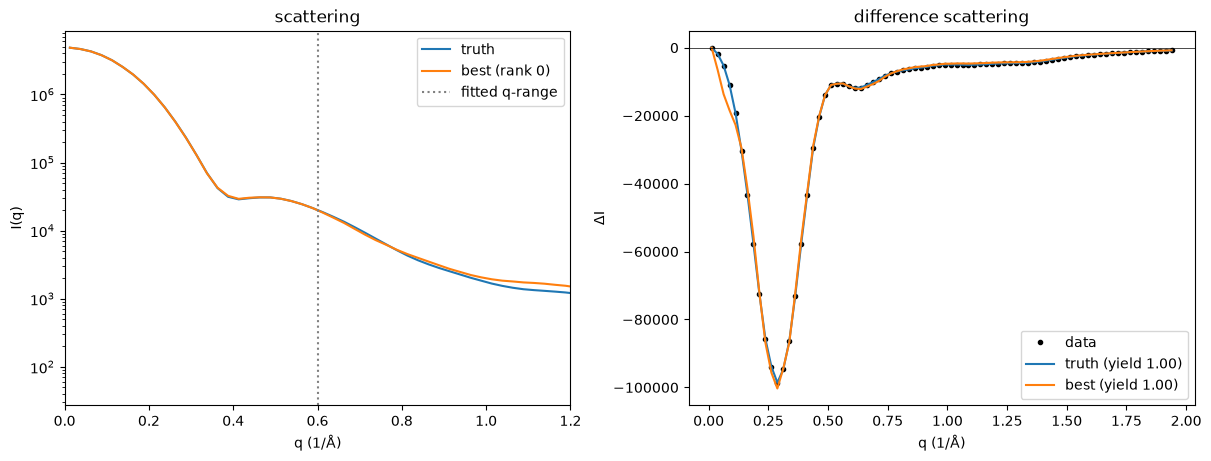

In [3]:
result_dir = "results/synthetic_class2_vacuum"
syn_dir = "data/synthetic_class2_vacuum"
h5_path = "data/1crn_41bb_1d61dv_5co.h5"

d = load_inputs(result_dir, syn_dir, h5_path)
settings, dark_fit = d["summary"]["settings"], d["summary"]["dark_fit"]
yld_best, yld_truth = d["summary"]["candidates"][0]["yield"], d["truth_cfg"]["pa_yield"]
qmax, dv = settings["qmax"], d["dv"]

# Densities
print_metrics(d["best"], d["truth"], d["dark"], qmax, dv)
plot_changes(d["truth"], d["best"], d["dark"])
plot_densities(d["truth"], d["best"], yld_best, "full resolution")
plot_densities(lowpass(d["truth"], qmax, dv), lowpass(d["best"], qmax, dv), yld_best,
               f"filtered to q ≤ {qmax} 1/Å (≈ {2 * numpy.pi / qmax:.0f} Å)")

# Scattering
q, I_dark = scattering(d["dark"], dv, settings["rho_bulk"], dark_fit, settings["padding"])
_, I_truth = scattering(d["truth"], dv, settings["rho_bulk"], dark_fit, settings["padding"])
_, I_best = scattering(d["best"], dv, settings["rho_bulk"], dark_fit, settings["padding"])
dI_truth = delta_I(I_truth, I_dark, q, d["q_data"], yld_truth, dark_fit["scale"])
dI_best = delta_I(I_best, I_dark, q, d["q_data"], yld_best, dark_fit["scale"])
plot_scattering(q, I_truth, I_best, qmax, d["q_data"], d["dI_data"], dI_truth, dI_best, yld_truth, yld_best)